#### EDA on COVID-19 Data Explore spread patterns, recovery rates, and trends over time.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("covid_eda_sample.csv")
print(df)

          Date Country  Confirmed  Recovered  Deaths
0   2020-03-01   India          3          0       0
1   2020-04-01   India       1397        123      35
2   2020-05-01   India      35043       9068    1152
3   2020-06-01   India     190535      91819    5394
4   2020-07-01   India     585481     347979   17400
5   2020-08-01   India    1695988    1094374   36511
6   2020-09-01   India    3691166    2839882   65288
7   2020-10-01   India    6312584    5273201   98678
8   2020-11-01   India    8184082    7489068  122111
9   2020-12-01   India    9462801    8889585  137621
10  2021-01-01   India   10757610   10423125  154392
11  2021-02-01   India   11096731   10775969  157051
12  2021-03-01   India   12149335   11409000  162468
13  2021-04-01   India   19164969   15684406  211853
14  2021-05-01   India   28047534   24283929  329100
15  2021-06-01   India   30411262   29309407  399459
16  2021-07-01   India   30542635   29658078  402005
17  2021-08-01   India   32810845   31959827  

In [3]:
print(df.head())

         Date Country  Confirmed  Recovered  Deaths
0  2020-03-01   India          3          0       0
1  2020-04-01   India       1397        123      35
2  2020-05-01   India      35043       9068    1152
3  2020-06-01   India     190535      91819    5394
4  2020-07-01   India     585481     347979   17400


In [4]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Date       22 non-null     str  
 1   Country    22 non-null     str  
 2   Confirmed  22 non-null     int64
 3   Recovered  22 non-null     int64
 4   Deaths     22 non-null     int64
dtypes: int64(3), str(2)
memory usage: 1012.0 bytes
None


In [5]:
print(df.isnull().sum())

Date         0
Country      0
Confirmed    0
Recovered    0
Deaths       0
dtype: int64


### Statement
The dataset has 22 rows and 5 columns, with no missing values. `Date` is stored as text, so it is converted to a proper date in the next step.

In [6]:
df["Date"] = pd.to_datetime(df["Date"])

print(df.dtypes)
print("\nSummary statistics:")
print(df.describe())

Date         datetime64[us]
Country                 str
Confirmed             int64
Recovered             int64
Deaths                int64
dtype: object

Summary statistics:
                             Date     Confirmed     Recovered         Deaths
count                          22  2.200000e+01  2.200000e+01      22.000000
mean   2021-01-15 07:38:10.909091  1.554821e+07  1.471459e+07  208595.181818
min           2020-03-01 00:00:00  3.000000e+00  0.000000e+00       0.000000
25%           2020-08-08 18:00:00  2.194782e+06  1.530751e+06   43705.250000
50%           2021-01-16 12:00:00  1.092717e+07  1.059955e+07  155721.500000
75%           2021-06-23 12:00:00  3.050979e+07  2.957091e+07  401368.500000
max           2021-12-01 00:00:00  3.486158e+07  3.428745e+07  481080.000000
std                           NaN  1.389970e+07  1.356134e+07  181290.887741


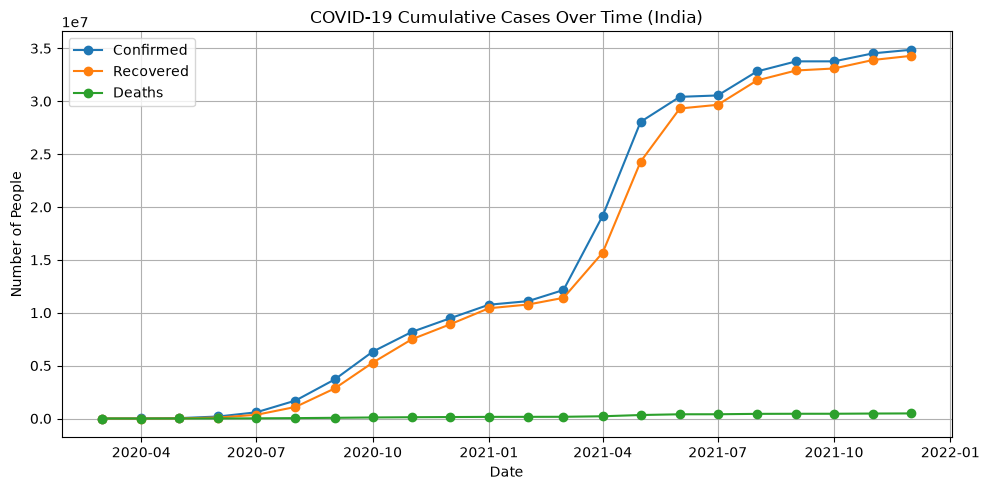


Latest totals:
Date         2021-12-01 00:00:00
Confirmed               34861579
Recovered               34287450
Deaths                    481080
Name: 21, dtype: object


In [7]:
plt.figure(figsize=(10, 5))
plt.plot(df["Date"], df["Confirmed"], marker="o", label="Confirmed")
plt.plot(df["Date"], df["Recovered"], marker="o", label="Recovered")
plt.plot(df["Date"], df["Deaths"], marker="o", label="Deaths")
plt.title("COVID-19 Cumulative Cases Over Time (India)")
plt.xlabel("Date")
plt.ylabel("Number of People")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nLatest totals:")
print(df.iloc[-1][["Date", "Confirmed", "Recovered", "Deaths"]])

### Statement
Confirmed cases grew from 3 in March 2020 to 34,861,579 by December 2021. Over the same period 34,287,450 people recovered and 481,080 died. The curve rose steeply in two phases: from mid-2020 to late 2020, and again in April-May 2021. It was almost flat from October 2021 onward.

New cases added since the previous month's snapshot:
         Date  New_Cases
0  2020-03-01        3.0
1  2020-04-01     1394.0
2  2020-05-01    33646.0
3  2020-06-01   155492.0
4  2020-07-01   394946.0
5  2020-08-01  1110507.0
6  2020-09-01  1995178.0
7  2020-10-01  2621418.0
8  2020-11-01  1871498.0
9  2020-12-01  1278719.0
10 2021-01-01  1294809.0
11 2021-02-01   339121.0
12 2021-03-01  1052604.0
13 2021-04-01  7015634.0
14 2021-05-01  8882565.0
15 2021-06-01  2363728.0
16 2021-07-01   131373.0
17 2021-08-01  2268210.0
18 2021-09-01   955447.0
19 2021-10-01      415.0
20 2021-11-01   759375.0
21 2021-12-01   335497.0


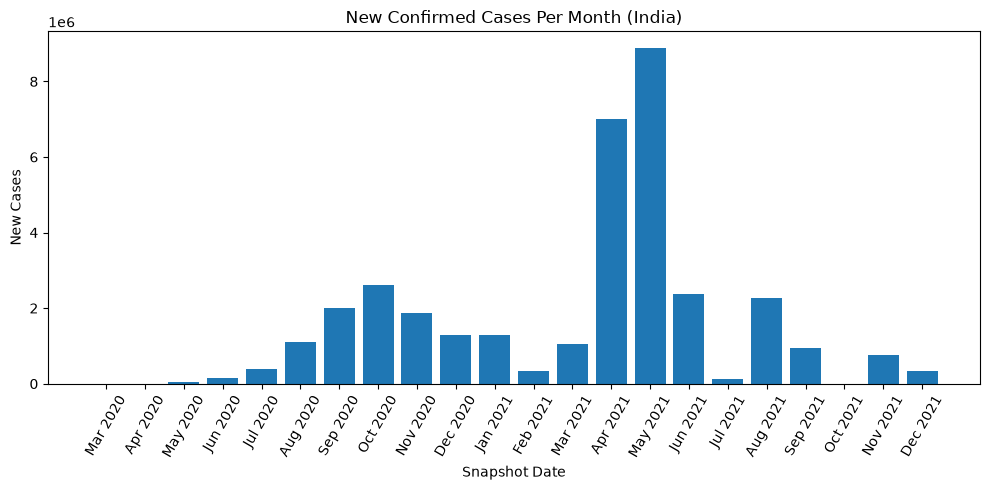


Biggest jump: 01 May 2021 -> 8882565 new cases


In [8]:
df["New_Cases"] = df["Confirmed"].diff().fillna(df["Confirmed"])

print("New cases added since the previous month's snapshot:")
print(df[["Date", "New_Cases"]])

plt.figure(figsize=(10, 5))
plt.bar(df["Date"].dt.strftime("%b %Y"), df["New_Cases"])
plt.title("New Confirmed Cases Per Month (India)")
plt.xlabel("Snapshot Date")
plt.ylabel("New Cases")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

peak = df.loc[df["New_Cases"].idxmax()]
print("\nBiggest jump:", peak["Date"].strftime("%d %b %Y"), "->", int(peak["New_Cases"]), "new cases")

### Statement
The highest increase in new cases was 8,882,565 by 1 May 2021, followed by 7,015,634 by 1 April 2021. By 1 October 2020, the increase was 2,621,418. The lowest increase was 415 cases by 1 October 2021.

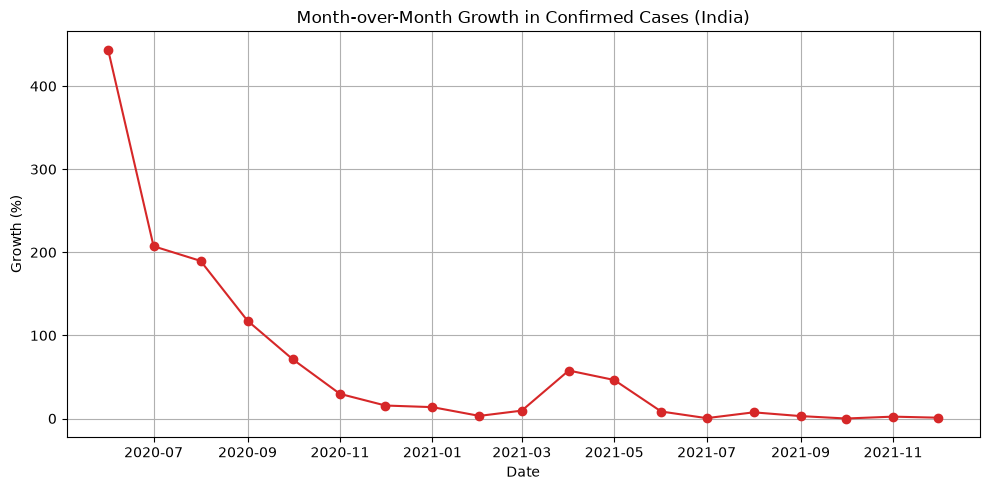

         Date  Growth_Rate
3  2020-06-01       443.72
4  2020-07-01       207.28
5  2020-08-01       189.67
6  2020-09-01       117.64
7  2020-10-01        71.02
8  2020-11-01        29.65
9  2020-12-01        15.62
10 2021-01-01        13.68
11 2021-02-01         3.15
12 2021-03-01         9.49
13 2021-04-01        57.75
14 2021-05-01        46.35
15 2021-06-01         8.43
16 2021-07-01         0.43
17 2021-08-01         7.43
18 2021-09-01         2.91
19 2021-10-01         0.00
20 2021-11-01         2.25
21 2021-12-01         0.97


In [9]:
df["Growth_Rate"] = df["Confirmed"].pct_change() * 100


growth = df[df["Date"] >= "2020-06-01"]

plt.figure(figsize=(10, 5))
plt.plot(growth["Date"], growth["Growth_Rate"], marker="o", color="tab:red")
plt.title("Month-over-Month Growth in Confirmed Cases (India)")
plt.xlabel("Date")
plt.ylabel("Growth (%)")
plt.grid(True)
plt.tight_layout()
plt.show()

print(growth[["Date", "Growth_Rate"]].round({"Growth_Rate": 2}))

### Statement

Growth was very high in June 2020 at 443.72%. It slowed to 3.15% in February 2021, then increased again during the second wave, reaching 57.75% in April and 46.35% in May 2021. By July and December 2021, growth had fallen to 0.43% and 0.97%, showing a slowdown in the spread.

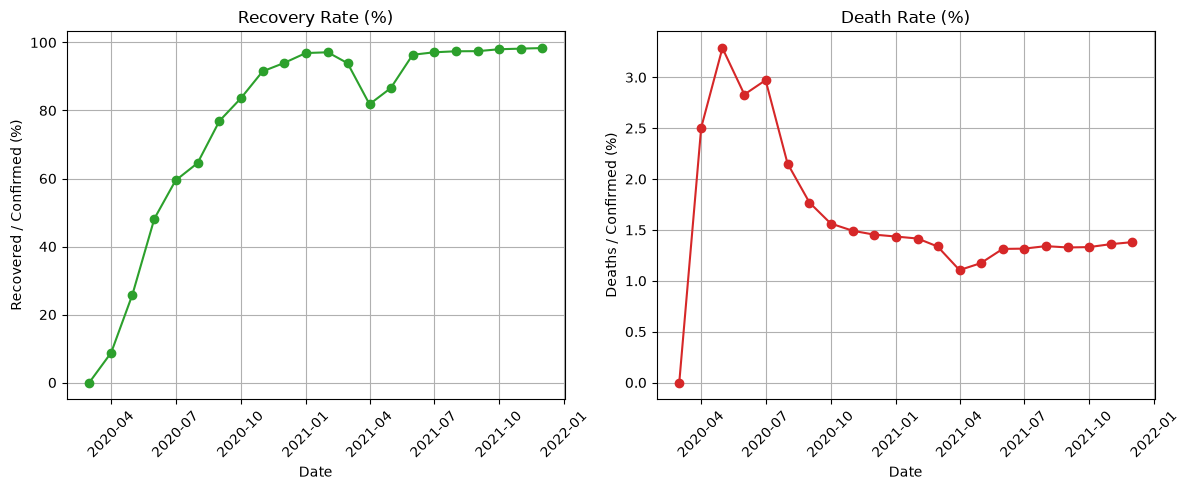

         Date  Recovery_Rate  Death_Rate
0  2020-03-01           0.00        0.00
1  2020-04-01           8.80        2.51
2  2020-05-01          25.88        3.29
3  2020-06-01          48.19        2.83
4  2020-07-01          59.43        2.97
5  2020-08-01          64.53        2.15
6  2020-09-01          76.94        1.77
7  2020-10-01          83.53        1.56
8  2020-11-01          91.51        1.49
9  2020-12-01          93.94        1.45
10 2021-01-01          96.89        1.44
11 2021-02-01          97.11        1.42
12 2021-03-01          93.91        1.34
13 2021-04-01          81.84        1.11
14 2021-05-01          86.58        1.17
15 2021-06-01          96.38        1.31
16 2021-07-01          97.10        1.32
17 2021-08-01          97.41        1.34
18 2021-09-01          97.44        1.33
19 2021-10-01          98.00        1.33
20 2021-11-01          98.19        1.36
21 2021-12-01          98.35        1.38


In [10]:
df["Recovery_Rate"] = df["Recovered"] / df["Confirmed"] * 100
df["Death_Rate"] = df["Deaths"] / df["Confirmed"] * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(df["Date"], df["Recovery_Rate"], marker="o", color="tab:green")
axes[0].set_title("Recovery Rate (%)")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Recovered / Confirmed (%)")
axes[0].grid(True)
axes[0].tick_params(axis="x", rotation=45)

axes[1].plot(df["Date"], df["Death_Rate"], marker="o", color="tab:red")
axes[1].set_title("Death Rate (%)")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Deaths / Confirmed (%)")
axes[1].grid(True)
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

print(df[["Date", "Recovery_Rate", "Death_Rate"]].round({"Recovery_Rate": 2, "Death_Rate": 2}))

### Statement
The recovery rate climbed from 8.80% in April 2020 to **98.35%** by December 2021. It fell to 81.84% in April 2021, when many new cases arrived at once during the second wave, then recovered quickly. The death rate was highest at **3.29%** in May 2020, dropped to 1.11% by April 2021, and ended at 1.38%. Overall, a much larger share of patients recovered as the pandemic went on.

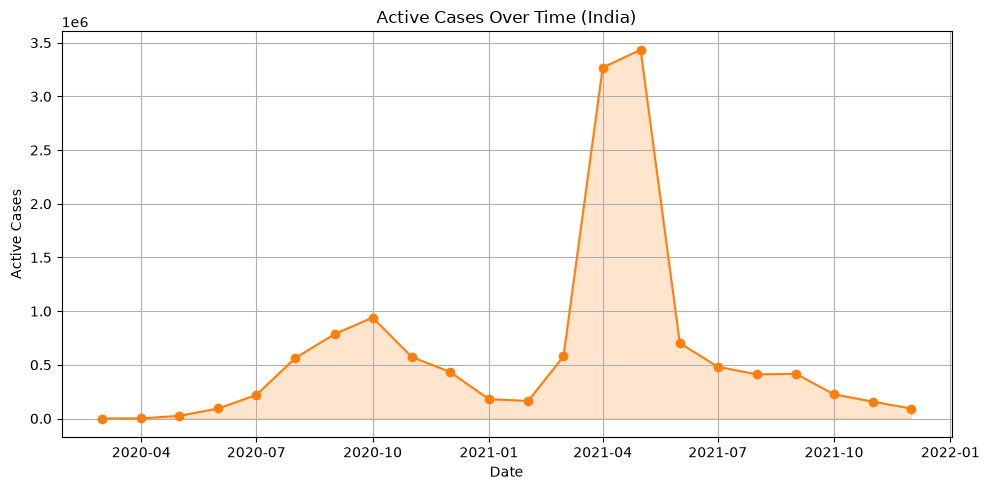

Peak active cases: 01 May 2021 -> 3434505


In [11]:
df["Active_Cases"] = df["Confirmed"] - df["Recovered"] - df["Deaths"]

plt.figure(figsize=(10, 5))
plt.plot(df["Date"], df["Active_Cases"], marker="o", color="tab:orange")
plt.fill_between(df["Date"], df["Active_Cases"], alpha=0.2, color="tab:orange")
plt.title("Active Cases Over Time (India)")
plt.xlabel("Date")
plt.ylabel("Active Cases")
plt.grid(True)
plt.tight_layout()
plt.show()

peak_active = df.loc[df["Active_Cases"].idxmax()]
print("Peak active cases:", peak_active["Date"].strftime("%d %b %Y"), "->", int(peak_active["Active_Cases"]))

### Statement
Active cases (Confirmed - Recovered - Deaths) show two clear waves. The first peaked at 940,705 on 1 October 2020. The second was much bigger, peaking at **3,434,505** on 1 May 2021, about 3.7 times the first peak. By December 2021 active cases had fallen to 93,049.